In [1]:

from pathlib import Path

import pandas as pd
import numpy as np

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "likely" /"tidytuesday" 

# Load local CSV files
absolute = pd.read_csv(
    DATA_DIR / "absolute_judgements.csv"
)

pairwise = pd.read_csv(
    DATA_DIR / "pairwise_comparisons.csv"
)

metadata = pd.read_csv(
    DATA_DIR / "respondent_metadata.csv"
)

# Inspect dataset dimensions
for name, df in {
    "absolute": absolute,
    "pairwise": pairwise,
    "metadata": metadata,
}.items():
    print(f"{name}: {df.shape}")


absolute: (98306, 4)
pairwise: (51740, 5)
metadata: (5174, 6)


In [2]:
# Calculate robust distribution statistics
distribution_summary = (
    absolute.groupby("term")["probability"]
    .agg(
        median="median",
        q10=lambda x: x.quantile(0.10),
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        q90=lambda x: x.quantile(0.90),
        std="std"
    )
)

distribution_summary["IQR"] = (
    distribution_summary["q75"]
    - distribution_summary["q25"]
)

display(
    distribution_summary.sort_values("median").round(2)
)

,median,q10,q25,q75,q90,std,IQR
term,,,,,,,
Almost No Chance,2.0,1.0,1.0,5.0,10.0,6.04,4.0
Remote Chance,5.0,1.0,3.0,10.0,20.0,9.93,7.0
Highly Unlikely,5.0,1.0,5.0,10.0,20.0,12.41,5.0
Chances are Slight,10.0,5.0,5.0,15.0,25.0,10.21,10.0
Improbable,10.0,1.0,5.0,20.0,30.0,11.60,15.0
Little Chance,10.0,5.0,5.0,15.0,20.0,8.08,10.0
Unlikely,20.0,5.0,10.0,25.0,30.0,11.30,15.0
Could Happen,40.0,15.0,25.0,50.0,60.0,18.23,25.0
May Happen,40.0,20.0,30.0,51.0,60.0,17.02,21.0


In [3]:
endpoint_summary = (
    absolute.assign(
        is_zero=absolute["probability"].eq(0),
        is_hundred=absolute["probability"].eq(100)
    )
    .groupby("term")
    .agg(
        zero_count=("is_zero", "sum"),
        hundred_count=("is_hundred", "sum"),
        total=("probability", "count")
    )
)

endpoint_summary["zero_pct"] = (
    endpoint_summary["zero_count"]
    / endpoint_summary["total"] * 100
)

endpoint_summary["hundred_pct"] = (
    endpoint_summary["hundred_count"]
    / endpoint_summary["total"] * 100
)

display(
    endpoint_summary.sort_values("zero_pct", ascending=False).round(2)
)

,zero_count,hundred_count,total,zero_pct,hundred_pct
term,,,,,
Improbable,222,1,5174,4.29,0.02
Almost No Chance,157,2,5174,3.03,0.04
Highly Unlikely,63,6,5174,1.22,0.12
Remote Chance,46,4,5174,0.89,0.08
Unlikely,34,5,5174,0.66,0.10
Little Chance,19,0,5174,0.37,0.00
Chances are Slight,12,3,5174,0.23,0.06
About Even,5,2,5174,0.10,0.04
Highly Likely,3,9,5174,0.06,0.17


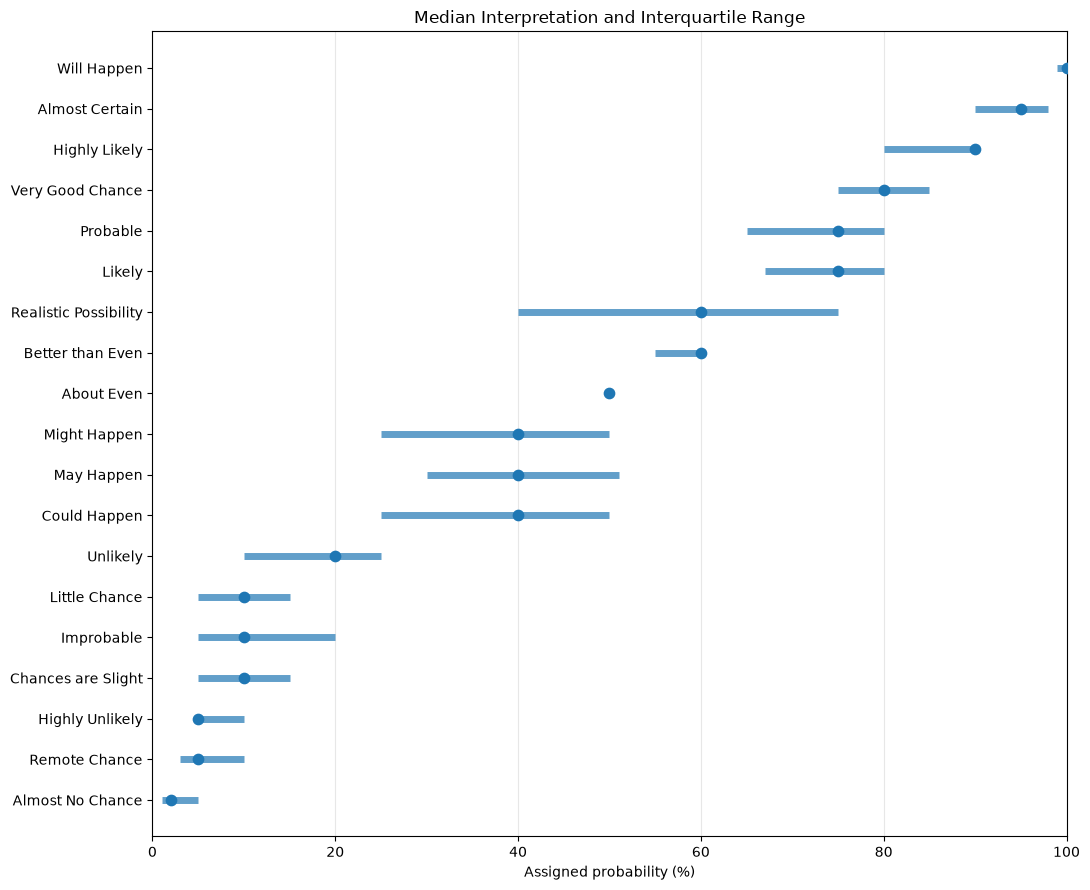

In [7]:
import matplotlib.pyplot as plt
plot_data = distribution_summary.sort_values("median")

fig, ax = plt.subplots(figsize=(11, 9))

y = np.arange(len(plot_data))

ax.hlines(
    y=y,
    xmin=plot_data["q25"],
    xmax=plot_data["q75"],
    linewidth=5,
    alpha=0.7
)

ax.scatter(
    plot_data["median"],
    y,
    s=55,
    zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(plot_data.index)
ax.set_xlim(0, 100)
ax.set_xlabel("Assigned probability (%)")
ax.set_title("Median Interpretation and Interquartile Range")

ax.grid(axis="x", alpha=0.3)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "likely" / "figures" / "distribution_summary.png",
    dpi=300
)
plt.show()